# Assignment 07: A First Machine Learning SDM

## BIO597 Spatial Analysis of Biodiversity

Repeat the workflow from Lab 07 for a Maine amphibian species of your choice. Focus on understanding what the model learns and what its predictions mean. You may reuse code from the lab.

## Deliverable

Submit this notebook with your completed code, figures, and short written answers, plus a saved suitability raster. There is no need to tune model settings or compare additional algorithms.


## 1. Import packages and load the data

Run this notebook from `docs/assignments`. Import the packages used in Lab 07. Load the two supplied files and display species counts.


In [2]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install rioxarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.1/39.1 MB 90.4 MB/s  0:00:006m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 56.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [rioxarray]/4 [xarray]o]
Note: you may need to restart the kernel to use updated packages.


In [5]:
# Import the packages used in Lab 07.

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import rioxarray
import xarray as xr

from sklearn.ensemble import RandomForestRegressor 
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

amphibians = gpd.read_file("../data/amphibians+bioclim.geojson")
climate = xr.open_dataset("../data/maine_bioclim.nc")

# Display species counts.

amphibians["species"].value_counts().head(12)

species
Pseudacris crucifer          1722
Aquarana clamitans           1656
Anaxyrus americanus          1581
Boreorana sylvatica          1522
Lithobates catesbeianus      1451
Ambystoma maculatum          1214
Plethodon cinereus           1125
Lithobates palustris         1007
Dryophytes versicolor         714
Notophthalmus viridescens     573
Lithobates pipiens            325
Hemidactylium scutatum        226
Name: count, dtype: int64

## 2. Choose your species

Choose a common species other than the wood frog, with at least 500 records. Keep records with coordinate uncertainty below 100 m, as in the lab.


Number of records: 1442


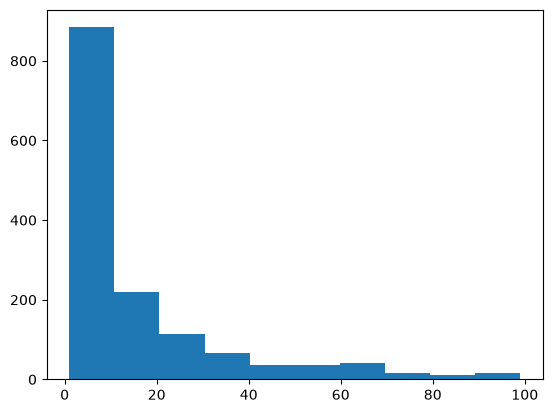

In [9]:
target_species = "Anaxyrus americanus"

# Select your species and apply the uncertainty filter.
# Store the result as presence and print its record count.

presence = amphibians[amphibians["species"] == target_species].copy()
presence = presence[presence["coordinateUncertaintyInMeters"] < 100].copy()

print("Number of records:", len(presence))

_ = plt.hist(presence["coordinateUncertaintyInMeters"])

In [11]:
climate

<xarray.Dataset> Size: 2MB
Dimensions:      (y: 109, x: 101)
Coordinates:
  * y            (y) float64 872B 47.48 47.44 47.4 47.35 ... 43.06 43.02 42.98
  * x            (x) float64 808B -71.1 -71.06 -71.02 ... -67.02 -66.98 -66.94
    band         int32 4B ...
Data variables: (12/20)
    bio_1        (y, x) float64 88kB ...
    bio_10       (y, x) float64 88kB ...
    bio_11       (y, x) float64 88kB ...
    bio_2        (y, x) float64 88kB ...
    bio_13       (y, x) float64 88kB ...
    bio_12       (y, x) float64 88kB ...
    ...           ...
    bio_5        (y, x) float64 88kB ...
    bio_8        (y, x) float64 88kB ...
    bio_19       (y, x) float64 88kB ...
    bio_18       (y, x) float64 88kB ...
    bio_9        (y, x) float64 88kB ...
    spatial_ref  int32 4B ...
Attributes:
    AREA_OR_POINT:       Area
    STATISTICS_MAXIMUM:  31.166666030884
    STATISTICS_MEAN:     nan
    STATISTICS_MINIMUM:  -54.759166717529
    STATISTICS_STDDEV:   nan
    scale_factor:        1.0
    add_offset:          0.0

In [12]:
presence

,gbifID,species,decimalLongitude,decimalLatitude,coordinateUncertaintyInMeters,year,bio_1,bio_10,bio_11,bio_2,...,bio_6,bio_4,bio_15,bio_14,bio_5,bio_8,bio_19,bio_18,bio_9,geometry
11,6520596403,Anaxyrus americanus,-70.456821,43.994143,9.0,2026.0,6.875500,18.782667,-5.710000,11.462334,...,-13.396000,987.470398,11.347319,84.0,26.136000,2.555333,285.0,266.0,17.938667,POINT (-70.45682 43.99414)
14,6520566821,Anaxyrus americanus,-70.684983,44.393545,5.0,2026.0,5.877167,18.200666,-7.208000,12.145000,...,-15.144000,1023.904968,13.020443,70.0,25.955999,1.270000,242.0,289.0,-6.012000,POINT (-70.68498 44.39354)
23,6520413611,Anaxyrus americanus,-69.822108,43.874055,10.0,2026.0,7.694676,18.833334,-3.831481,9.431944,...,-10.088889,915.900757,14.027859,77.0,25.222223,3.715741,296.0,250.0,18.269444,POINT (-69.82211 43.87406)
25,6520268523,Anaxyrus americanus,-69.017731,44.389835,2.0,2026.0,7.017667,18.583332,-5.118000,10.758667,...,-11.940000,955.339661,16.672430,82.0,25.803999,2.839333,295.0,255.0,18.583332,POINT (-69.01773 44.38984)
34,6520168034,Anaxyrus americanus,-68.857452,45.924545,9.0,2026.0,2.863000,15.930000,-10.804000,11.243333,...,-18.320000,1079.739014,15.799123,64.0,23.208000,15.930000,239.0,334.0,-9.733334,POINT (-68.85745 45.92454)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13574,1273853682,Anaxyrus americanus,-70.632843,43.391466,4.0,2016.0,7.875333,19.416000,-4.074667,11.921333,...,-11.248000,946.164307,13.141269,84.0,27.132000,3.459333,284.0,257.0,18.575333,POINT (-70.63284 43.39147)
13588,1269571772,Anaxyrus americanus,-70.160123,44.559859,2.0,2015.0,5.888167,18.213333,-7.286000,12.065001,...,-15.276000,1027.365601,9.467299,75.0,25.944000,1.376667,264.0,293.0,-6.076000,POINT (-70.16012 44.55986)
13589,1269571670,Anaxyrus americanus,-70.663403,44.758710,23.0,2012.0,4.215000,16.784666,-9.236000,12.183333,...,-17.063999,1050.876831,14.349178,65.0,24.348000,16.784666,225.0,306.0,-8.035334,POINT (-70.6634 44.75871)
13590,1269571659,Anaxyrus americanus,-70.160120,44.559855,5.0,2013.0,5.888167,18.213333,-7.286000,12.065001,...,-15.276000,1027.365601,9.467299,75.0,25.944000,1.376667,264.0,293.0,-6.076000,POINT (-70.16012 44.55986)


**Why did you choose this species?** Write one or two sentences. American toad are a common and hardy species.

## 3. Keep all climate variables available

As in Lab 07, make a list called `climate_variables` containing `bio_1` through `bio_19`. We will choose the model predictors after preparing the modeling table.


In [13]:
# Create climate_variables and display these columns at your species' records.

climate_variables = ["bio_" +str(number) for number in range(1, 20)]

presence[climate_variables].head()

,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,bio_9,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19
11,6.875500,11.462334,28.995077,987.470398,26.136000,-13.396000,39.531998,2.555333,17.938667,18.782667,-5.710000,1162.0,120.0,84.0,11.347319,332.0,258.0,266.0,285.0
14,5.877167,12.145000,29.549879,1023.904968,25.955999,-15.144000,41.099998,1.270000,-6.012000,18.200666,-7.208000,1101.0,115.0,70.0,13.020443,312.0,228.0,289.0,242.0
23,7.694676,9.431944,26.710979,915.900757,25.222223,-10.088889,35.311111,3.715741,18.269444,18.833334,-3.831481,1154.0,121.0,77.0,14.027859,337.0,245.0,250.0,296.0
25,7.017667,10.758667,28.504311,955.339661,25.803999,-11.940000,37.743999,2.839333,18.583332,18.583332,-5.118000,1205.0,136.0,82.0,16.672430,366.0,255.0,255.0,295.0
34,2.863000,11.243333,27.074102,1079.739014,23.208000,-18.320000,41.528000,15.930000,-9.733334,15.930000,-10.804000,1124.0,113.0,64.0,15.799123,334.0,222.0,334.0,239.0


## 4. Prepare presence and background tables

Use the prepared climate values at the occurrence records directly, as in the revised lab. We do not need to match records to raster cells or join tables by coordinates.

The code below prepares the climate grid for background sampling and mapping. Each grid row is a cell, but each presence row is an occurrence record. Several presence records may therefore describe the same climate cell.


In [14]:
grid = climate[climate_variables].to_dataframe().reset_index()
grid = grid[["x", "y"] + climate_variables]
grid = grid.dropna(subset=climate_variables)
grid.head()


,x,y,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,...,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19
146,-69.229167,47.437500,2.610167,10.487667,24.623560,1133.966675,23.148001,-19.444000,42.592003,16.066000,...,16.066000,-12.065333,1093.0,110.0,67.0,13.786905,317.0,227.0,317.0,231.0
147,-69.187500,47.437500,2.620167,10.551667,24.738974,1134.299316,23.200001,-19.452000,42.652000,16.072001,...,16.072001,-12.078667,1080.0,110.0,66.0,14.227962,316.0,223.0,316.0,228.0
148,-69.145833,47.437500,2.786333,10.607333,24.855499,1130.561035,23.344000,-19.332001,42.676003,16.170000,...,16.170000,-11.888667,1043.0,108.0,63.0,14.921009,307.0,211.0,307.0,222.0
246,-69.270833,47.395833,2.161333,10.447333,24.595850,1134.809448,22.668001,-19.808001,42.476002,15.676667,...,15.676667,-12.473333,1130.0,116.0,69.0,14.441315,332.0,233.0,332.0,237.0
247,-69.229167,47.395833,2.441500,10.566333,24.831577,1130.958252,22.968000,-19.584000,42.552002,15.872000,...,15.872000,-12.190666,1099.0,113.0,67.0,14.589335,323.0,226.0,323.0,231.0


In [16]:
# Keep the prepared predictors and remove records with missing climate values.
presence_data = presence[climate_variables].dropna().copy()
presence_data["observed"] = 1

print("Usable presence records:", len(presence_data))
presence_data.head()


Usable presence records: 1442


,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,bio_9,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19,observed
11,6.875500,11.462334,28.995077,987.470398,26.136000,-13.396000,39.531998,2.555333,17.938667,18.782667,-5.710000,1162.0,120.0,84.0,11.347319,332.0,258.0,266.0,285.0,1
14,5.877167,12.145000,29.549879,1023.904968,25.955999,-15.144000,41.099998,1.270000,-6.012000,18.200666,-7.208000,1101.0,115.0,70.0,13.020443,312.0,228.0,289.0,242.0,1
23,7.694676,9.431944,26.710979,915.900757,25.222223,-10.088889,35.311111,3.715741,18.269444,18.833334,-3.831481,1154.0,121.0,77.0,14.027859,337.0,245.0,250.0,296.0,1
25,7.017667,10.758667,28.504311,955.339661,25.803999,-11.940000,37.743999,2.839333,18.583332,18.583332,-5.118000,1205.0,136.0,82.0,16.672430,366.0,255.0,255.0,295.0,1
34,2.863000,11.243333,27.074102,1079.739014,23.208000,-18.320000,41.528000,15.930000,-9.733334,15.930000,-10.804000,1124.0,113.0,64.0,15.799123,334.0,222.0,334.0,239.0,1


In [17]:
# Sample available environments, using one background row per presence record.
background = grid.sample(n=len(presence_data), random_state=597).copy()
background["observed"] = 0

model_data = pd.concat([presence_data, background], ignore_index=True)
model_data["observed"].value_counts()


observed
1    1442
0    1442
Name: count, dtype: int64

The missing-value cleanup keeps incomplete presence records out of both models. `random_state=597` makes the background sample repeatable. Background is sampled from the full valid grid, so it can include cells where the species has been recorded. It represents available environments, not confirmed absences.

## 5. Define predictors and response

Start with `features = ["bio_1"]`, annual mean temperature, to connect with last week's model. Set `X` to this predictor column and `y` to the `observed` labels. Only the selected climate columns belong in `X`; the background's coordinate columns are for mapping.


In [18]:
# Set features to bio_1 only.
# Define X and y, following Lab 07.

features = ["bio_1"]
X = model_data[features]
y = model_data["observed"]

X.head()


,bio_1
0,6.875500
1,5.877167
2,7.694676
3,7.017667
4,2.863000


## 6. Split, fit, and predict

Split `model_data` into `train_data` (75%) and `test_data` (25%) with `random_state=597``, as in the lab

Fit a `RandomForestRegressor` using only `bio_1`, with 100 trees, `min_samples_leaf=5`, and `random_state=597`.


In [22]:
# Split model_data into train_data and test_data.
# Define X_train, X_test, y_train, and y_test using features and observed.
# Create model and fit it to the training data.
# Predict suitability for X_test.


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

print("Training cells:", len(X_train))
print("Test cells:", len(X_test))

model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=5,
    random_state=42,
)
model.fit(X_train, y_train)

test_prediction = model.predict(X_test)
print(test_prediction[:10])
print(y_test[:10].values)

Training cells: 2163
Test cells: 721
[0.75519702 0.01841841 0.30601665 0.09602567 0.75519702 0.81436369
 0.88018142 0.69758945 0.18720889 0.90294542]
[1 0 0 0 0 1 1 1 0 1]


## 7. Check the BIO1-only predictions

Calculate mean absolute error and store it as `bio1_error`. Plot test predictions for presence and background cells in overlapping histograms, as in the lab.


BIO1-only MAE: 0.348


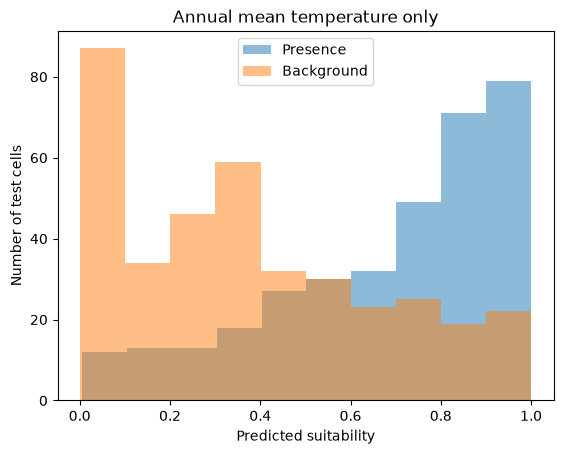

In [24]:
# Calculate and print bio1_error.
# Plot the predicted score distributions for the two test labels.

test_prediction = model.predict(X_test)
bio1_error = mean_absolute_error(y_test, test_prediction)
print("BIO1-only MAE:", round(bio1_error, 3))

plt.hist(test_prediction[y_test == 1], alpha=0.5, label="Presence")
plt.hist(test_prediction[y_test == 0], alpha=0.5, label="Background")
plt.xlabel("Predicted suitability")
plt.ylabel("Number of test cells")
plt.title("Annual mean temperature only")
plt.legend()
plt.show()


**Interpretation:** Do test presence cells generally receive higher scores? Why should we use withheld cells to check the model? Yes, the test presence cells generally receive higher scores (if you gave a practice test and the final is the same as the practice test, that is the same as using the reocrds that were used to train the model to test the model). 

## 8. Add precipitation and compare MAE

Choose three new bioclim variables to test (you can look up the meanings of the variables
in the [bioclimatic variables documentation](https://www.worldclim.org/data/bioclim.html))

Change `features` to `["bio_X", "bio_XX", "bio_XX"]` (replacing the "X" values with the integer
index of the bioclim variables you chose). Create a new feature table (`X`) selecting just the features of interest and perform a new test/train split. Fit a new forest with these three predictors and calculate `three_variable_error`. Print both MAEs together.


In [27]:
# Select the three predictor columns from the existing training and test tables.
# Fit three_variable_model and predict the same withheld cells.
# Calculate three_variable_error and print it beside bio1_error.

features = ["bio_12", "bio_13", "bio_14"]

X = model_data[features]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

three_variable_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=2,
)

three_variable_model.fit(X_train, y_train)

three_variable_prediction = three_variable_model.predict(X_test)

three_variable_error = mean_absolute_error(y_test, three_variable_prediction)
bio12_error = mean_absolute_error(y_test, test_prediction)

print("BIO12-only MAE:", round(bio12_error, 3))
print("BIO12 + BIO13 + BIO14 MAE:", round(three_variable_error, 3))

BIO12-only MAE: 0.348
BIO12 + BIO13 + BIO14 MAE: 0.337


**Interpretation:** Did the three new bioclim variables improve prediction error for your species? Explain why the new conditions you chose may or may not be relevant biologically.

## 9. Make a suitability map

Fit a new `final_model` using all modeling rows and the three predictors. Predict scores for `grid[features]`. Use the plotting recipe from Lab 07 to turn the suitability column into a raster and map it from 0 to 1.


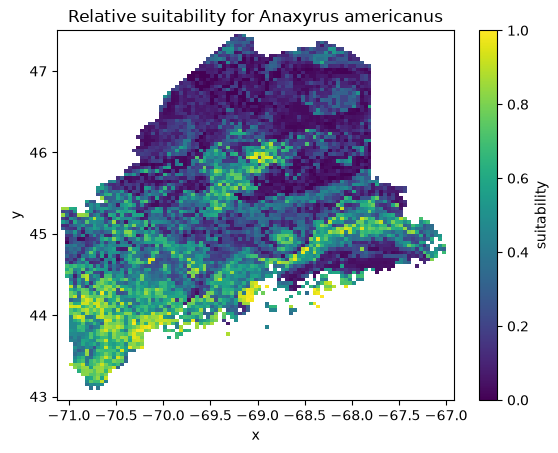

In [29]:
# Update X to include all three predictors.
# Fit final_model with the same forest settings.
# Add grid["suitability"], convert it to a raster named suitability, and plot it.

X = model_data[features]
final_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=597,
)
final_model.fit(X, y)
grid["suitability"] = final_model.predict(grid[features])

suitability = grid.set_index(["y", "x"])["suitability"].to_xarray()
suitability = suitability.reindex(y=climate.y, x=climate.x)

suitability.plot(vmin=0, vmax=1, cmap="viridis")
plt.title(f"Relative suitability for {target_species}")
plt.show()

**Interpretation:** Which parts of Maine receive high scores? Why should we describe these as relative suitability rather than probability of occurrence? The coast and western mountain ranges of Maine received high scores. This is relative suitability rather than probability of occurence because we ar eonly looking at climatic variables and we did not include biotic factors.

## 10. Plot variable importance

Use `final_model.feature_importances_` and `pd.Series()` as in the lab to make a bar plot for the three predictors.


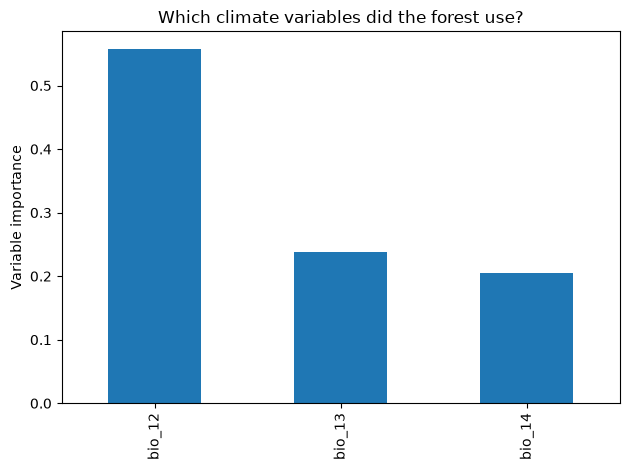

In [30]:
# Make and label a variable-importance plot.

importance = pd.Series(final_model.feature_importances_, index=features)
importance.plot.bar()
plt.ylabel("Variable importance")
plt.title("Which climate variables did the forest use?")
plt.tight_layout()
plt.show()

**Interpretation:** Which variable did your forest use most? Give one reason why this does not establish an ecological cause.

## 11. Save your map

Save `suitability` as `Assignment07_suitability.tif` using the same CRS and export commands as the lab.


In [31]:
# Assign EPSG:4326 and save the suitability raster.

suitability = suitability.rio.write_crs("EPSG:4326")
suitability.rio.to_raster("Assignment07_suitability.tif")


## 12. Run the training and prediction again including all 19 bioclim variables

**Think about:** Do you predict that more variables will improve the MAE of the model?

In [1]:
# Run the full analysis again but this time include all 19 bioclim variables
# feel free to copy/paste from cells above

In [32]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [33]:
pip install rioxarray

Note: you may need to restart the kernel to use updated packages.


In [34]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import rioxarray
import xarray as xr

from sklearn.ensemble import RandomForestRegressor 
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

amphibians = gpd.read_file("../data/amphibians+bioclim.geojson")
climate = xr.open_dataset("../data/maine_bioclim.nc")

# Display species counts.

amphibians["species"].value_counts().head(12)

species
Pseudacris crucifer          1722
Aquarana clamitans           1656
Anaxyrus americanus          1581
Boreorana sylvatica          1522
Lithobates catesbeianus      1451
Ambystoma maculatum          1214
Plethodon cinereus           1125
Lithobates palustris         1007
Dryophytes versicolor         714
Notophthalmus viridescens     573
Lithobates pipiens            325
Hemidactylium scutatum        226
Name: count, dtype: int64

Number of records: 1442


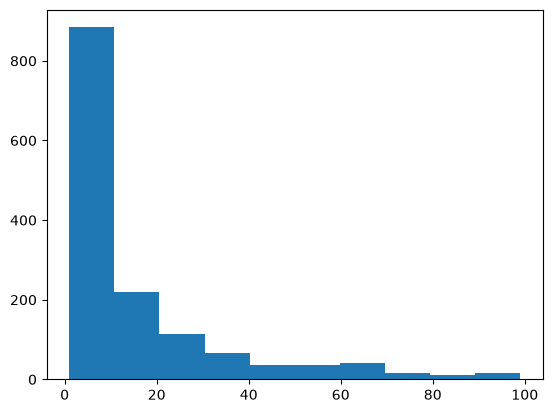

In [35]:
target_species = "Anaxyrus americanus"

# Select your species and apply the uncertainty filter.
# Store the result as presence and print its record count.

presence = amphibians[amphibians["species"] == target_species].copy()
presence = presence[presence["coordinateUncertaintyInMeters"] < 100].copy()

print("Number of records:", len(presence))

_ = plt.hist(presence["coordinateUncertaintyInMeters"])

In [36]:
# Create climate_variables and display these columns at your species' records.

climate_variables = ["bio_" +str(number) for number in range(1, 20)]

presence[climate_variables].head()

,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,bio_9,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19
11,6.875500,11.462334,28.995077,987.470398,26.136000,-13.396000,39.531998,2.555333,17.938667,18.782667,-5.710000,1162.0,120.0,84.0,11.347319,332.0,258.0,266.0,285.0
14,5.877167,12.145000,29.549879,1023.904968,25.955999,-15.144000,41.099998,1.270000,-6.012000,18.200666,-7.208000,1101.0,115.0,70.0,13.020443,312.0,228.0,289.0,242.0
23,7.694676,9.431944,26.710979,915.900757,25.222223,-10.088889,35.311111,3.715741,18.269444,18.833334,-3.831481,1154.0,121.0,77.0,14.027859,337.0,245.0,250.0,296.0
25,7.017667,10.758667,28.504311,955.339661,25.803999,-11.940000,37.743999,2.839333,18.583332,18.583332,-5.118000,1205.0,136.0,82.0,16.672430,366.0,255.0,255.0,295.0
34,2.863000,11.243333,27.074102,1079.739014,23.208000,-18.320000,41.528000,15.930000,-9.733334,15.930000,-10.804000,1124.0,113.0,64.0,15.799123,334.0,222.0,334.0,239.0


In [37]:
grid = climate[climate_variables].to_dataframe().reset_index()
grid = grid[["x", "y"] + climate_variables]
grid = grid.dropna(subset=climate_variables)
grid.head()

,x,y,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,...,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19
146,-69.229167,47.437500,2.610167,10.487667,24.623560,1133.966675,23.148001,-19.444000,42.592003,16.066000,...,16.066000,-12.065333,1093.0,110.0,67.0,13.786905,317.0,227.0,317.0,231.0
147,-69.187500,47.437500,2.620167,10.551667,24.738974,1134.299316,23.200001,-19.452000,42.652000,16.072001,...,16.072001,-12.078667,1080.0,110.0,66.0,14.227962,316.0,223.0,316.0,228.0
148,-69.145833,47.437500,2.786333,10.607333,24.855499,1130.561035,23.344000,-19.332001,42.676003,16.170000,...,16.170000,-11.888667,1043.0,108.0,63.0,14.921009,307.0,211.0,307.0,222.0
246,-69.270833,47.395833,2.161333,10.447333,24.595850,1134.809448,22.668001,-19.808001,42.476002,15.676667,...,15.676667,-12.473333,1130.0,116.0,69.0,14.441315,332.0,233.0,332.0,237.0
247,-69.229167,47.395833,2.441500,10.566333,24.831577,1130.958252,22.968000,-19.584000,42.552002,15.872000,...,15.872000,-12.190666,1099.0,113.0,67.0,14.589335,323.0,226.0,323.0,231.0


In [38]:
# Keep the prepared predictors and remove records with missing climate values.
presence_data = presence[climate_variables].dropna().copy()
presence_data["observed"] = 1

print("Usable presence records:", len(presence_data))
presence_data.head()

Usable presence records: 1442


,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,bio_9,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19,observed
11,6.875500,11.462334,28.995077,987.470398,26.136000,-13.396000,39.531998,2.555333,17.938667,18.782667,-5.710000,1162.0,120.0,84.0,11.347319,332.0,258.0,266.0,285.0,1
14,5.877167,12.145000,29.549879,1023.904968,25.955999,-15.144000,41.099998,1.270000,-6.012000,18.200666,-7.208000,1101.0,115.0,70.0,13.020443,312.0,228.0,289.0,242.0,1
23,7.694676,9.431944,26.710979,915.900757,25.222223,-10.088889,35.311111,3.715741,18.269444,18.833334,-3.831481,1154.0,121.0,77.0,14.027859,337.0,245.0,250.0,296.0,1
25,7.017667,10.758667,28.504311,955.339661,25.803999,-11.940000,37.743999,2.839333,18.583332,18.583332,-5.118000,1205.0,136.0,82.0,16.672430,366.0,255.0,255.0,295.0,1
34,2.863000,11.243333,27.074102,1079.739014,23.208000,-18.320000,41.528000,15.930000,-9.733334,15.930000,-10.804000,1124.0,113.0,64.0,15.799123,334.0,222.0,334.0,239.0,1


In [39]:
# Sample available environments, using one background row per presence record.
background = grid.sample(n=len(presence_data), random_state=597).copy()
background["observed"] = 0

model_data = pd.concat([presence_data, background], ignore_index=True)
model_data["observed"].value_counts()

observed
1    1442
0    1442
Name: count, dtype: int64

In [41]:
# Set features to bio_1 only.
# Define X and y, following Lab 07.

features = ["bio_1", "bio_2", "bio_3", "bio_4", "bio_5", "bio_6", "bio_7", "bio_8", "bio_9", "bio_10", "bio_11", "bio_12", "bio_13", "bio_14", "bio_15", "bio_16", "bio_17", "bio_18", "bio_19"]
X = model_data[features]
y = model_data["observed"]

X.head()

,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,bio_9,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19
0,6.875500,11.462334,28.995077,987.470398,26.136000,-13.396000,39.531998,2.555333,17.938667,18.782667,-5.710000,1162.0,120.0,84.0,11.347319,332.0,258.0,266.0,285.0
1,5.877167,12.145000,29.549879,1023.904968,25.955999,-15.144000,41.099998,1.270000,-6.012000,18.200666,-7.208000,1101.0,115.0,70.0,13.020443,312.0,228.0,289.0,242.0
2,7.694676,9.431944,26.710979,915.900757,25.222223,-10.088889,35.311111,3.715741,18.269444,18.833334,-3.831481,1154.0,121.0,77.0,14.027859,337.0,245.0,250.0,296.0
3,7.017667,10.758667,28.504311,955.339661,25.803999,-11.940000,37.743999,2.839333,18.583332,18.583332,-5.118000,1205.0,136.0,82.0,16.672430,366.0,255.0,255.0,295.0
4,2.863000,11.243333,27.074102,1079.739014,23.208000,-18.320000,41.528000,15.930000,-9.733334,15.930000,-10.804000,1124.0,113.0,64.0,15.799123,334.0,222.0,334.0,239.0


In [42]:
# Split model_data into train_data and test_data.
# Define X_train, X_test, y_train, and y_test using features and observed.
# Create model and fit it to the training data.
# Predict suitability for X_test.


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

print("Training cells:", len(X_train))
print("Test cells:", len(X_test))

model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=5,
    random_state=42,
)
model.fit(X_train, y_train)

test_prediction = model.predict(X_test)
print(test_prediction[:10])
print(y_test[:10].values)

Training cells: 2163
Test cells: 721
[0.89483419 0.07545521 0.08221281 0.03798063 0.63471518 0.82716145
 0.98767424 0.97992063 0.49407661 0.95910101]
[1 0 0 0 0 1 1 1 0 1]


BIO1-only MAE: 4.997
BIO2-only MAE: 10.983
BIO3-only MAE: 27.938
BIO4-only MAE: 1024.854
BIO5-only MAE: 24.763
BIO6-only MAE: 15.679
BIO7-only MAE: 39.916
BIO8-only MAE: 7.426
BIO9-only MAE: 11.387
BIO10-only MAE: 17.319
BIO11-only MAE: 8.093
BIO12-only MAE: 1116.923
BIO13-only MAE: 115.051
BIO14-only MAE: 70.693
BIO15-only MAE: 13.591
BIO16-only MAE: 323.295
BIO17-only MAE: 232.507
BIO18-only MAE: 283.309
BIO19-only MAE: 257.642


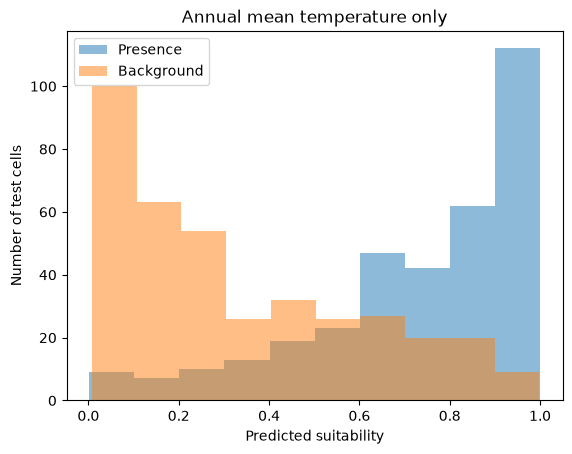

All 19 BIO Variables MAE: 0.299


In [54]:
test_prediction = model.predict(X_test)

for i in range(1, 20):
    column_name = f'bio_{i}'  
    bio_error = mean_absolute_error(X_test[column_name], test_prediction)
    print(f"BIO{i}-only MAE: {round(bio_error, 3)}")

plt.hist(test_prediction[y_test == 1], alpha=0.5, label="Presence")
plt.hist(test_prediction[y_test == 0], alpha=0.5, label="Background")
plt.xlabel("Predicted suitability")
plt.ylabel("Number of test cells")
plt.title("Annual mean temperature only")
plt.legend()
plt.show()

features = [
    "bio_1", "bio_2", "bio_3", "bio_4", "bio_5", "bio_6", "bio_7", "bio_8", 
    "bio_9", "bio_10", "bio_11", "bio_12", "bio_13", "bio_14", "bio_15", 
    "bio_16", "bio_17", "bio_18", "bio_19"
]

X = model_data[features]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

all_variable_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=2,
)

all_variable_model.fit(X_train, y_train)

all_variable_prediction = all_variable_model.predict(X_test)

all_variable_error = mean_absolute_error(y_test, all_variable_prediction)

print("All 19 BIO Variables MAE:", round(all_variable_error, 3))

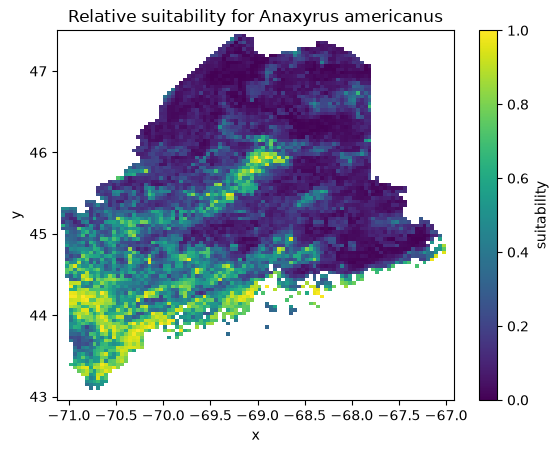

In [55]:
# Update X to include all three predictors.
# Fit final_model with the same forest settings.
# Add grid["suitability"], convert it to a raster named suitability, and plot it.

X = model_data[features]
final_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=597,
)
final_model.fit(X, y)
grid["suitability"] = final_model.predict(grid[features])

suitability = grid.set_index(["y", "x"])["suitability"].to_xarray()
suitability = suitability.reindex(y=climate.y, x=climate.x)

suitability.plot(vmin=0, vmax=1, cmap="viridis")
plt.title(f"Relative suitability for {target_species}")
plt.show()

In [56]:
suitability = suitability.rio.write_crs("EPSG:4326")
suitability.rio.to_raster("Assignment07_suitability_all_bio_variables.tif")

## Final reflection

Answer in two or three sentences per question.

1. How does this week's BIO1-only random forest differ from last week's hand-built temperature curve? For thhe BIO1-only random forest, it did the hard work for us by testing the random darta-splits to see where presence vs. background changes. The BIO1-only random forest also matches the specific training data we used where the hand-built temperature curve did not.
2. What did the comparison with three predictors teach you? Would you expect more predictors always to reduce test error? It imrpvoes model performance because you are actually adding in relevant environmental variables. And no, adding more predictors does not always reduce test error because you can have overlap between variables that reduce the ability of the model to function properly.
3. Several presence records can share a climate cell. Why might a random split then make prediction look easier than predicting a new location? It's like the example of being given the practice exam and the final being exactly the same as the practice exam or being somewhat similar to the practice exam or it being completely different than the practice exam. This means that the model cannot rely on exact matches if it is somewhat similar or completely different which results in a much more honest test error. 
4. Name one habitat variable or sampling issue missing from your model. How might it affect the map? Biotic factors like predators, etc. that could impact suitability. It also once again ignores sampling bias because amphibians are often seen along high human traffic areas.

## Submit your work

Restart the kernel and run the notebook from top to bottom. Check your figures, written answers, both MAEs, and saved raster. Commit and push the notebook and raster to your class GitHub repository.

```bash
git add docs/assignments/Assignment-07-MachineLearningSDM.ipynb docs/assignments/Assignment07_suitability.tif
git commit -m "Complete machine learning SDM assignment"
git push
```
